# 2016–2017 — AlphaGo and AlphaZero: Search + Learned Intuition

**Papers:** David Silver et al., *"Mastering the game of Go with deep neural networks and tree search"*, Nature (2016) (AlphaGo); *"Mastering the game of Go without human knowledge"*, Nature (2017) (AlphaGo Zero); *"A general reinforcement learning algorithm that masters chess, shogi, and Go through self-play"*, Science (2018) (AlphaZero). Monte Carlo Tree Search: Coulom (2006), Kocsis & Szepesvári (UCT, 2006).

In March 2016 AlphaGo beat Lee Sedol 4–1 at Go, a decade earlier than most experts expected. Go has ~$10^{170}$ positions, so neither brute-force search nor hand-written evaluation works. AlphaGo combined:
- a **policy network** $p(a\mid s)$: which moves look promising (intuition),
- a **value network** $v(s)$: who is winning from here (judgement),
- **Monte Carlo Tree Search (MCTS):** look ahead, but only along moves the policy suggests, and evaluate leaves with the value network instead of playing to the end.

**AlphaZero** removed all human data. It starts from random play and repeats:
1. Play games against itself, choosing each move by MCTS guided by the current network.
2. Train the network: the policy toward MCTS's visit distribution $\pi$ (search is a **policy improvement operator**), and the value toward the final result $z$:
$$\mathcal L = (z - v)^2 - \pi^\top\log p + c\lVert\theta\rVert^2$$

The same algorithm, unchanged, mastered chess, shogi and Go. Here it learns tic-tac-toe from scratch, a game small enough that we can compute **perfect play** and check exactly how good the learned policy is.

![Diagram: AlphaGo Zero / AlphaZero (Silver et al., 2017)](https://raw.githubusercontent.com/babushkai/neuralnetwork/main/assets/diagrams/40_2017_alphazero.png)

In [1]:
import os, math, random, time
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

def get_device():
    """CUDA > Apple MPS > CPU. Force one with the env var NN_DEVICE=cpu|cuda|mps."""
    forced = os.environ.get("NN_DEVICE")
    if forced:
        return torch.device(forced)
    if torch.cuda.is_available():
        return torch.device("cuda")
    if torch.backends.mps.is_available():
        return torch.device("mps")
    return torch.device("cpu")

def seed_everything(seed=0):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)

device = get_device()
torch.set_flush_denormal(True)   # tiny "denormal" floats are extremely slow on CPUs; treat them as 0
seed_everything(0)
print("PyTorch", torch.__version__, "| device:", device)
device = torch.device("cpu")
torch.set_num_threads(1)
from functools import lru_cache

PyTorch 2.15.0 | device: mps


In [2]:
LINES = [(0, 1, 2), (3, 4, 5), (6, 7, 8), (0, 3, 6), (1, 4, 7), (2, 5, 8), (0, 4, 8), (2, 4, 6)]
def winner(b):
    for i, j, k in LINES:
        if b[i] != 0 and b[i] == b[j] == b[k]: return b[i]
    return 0
def legal(b): return [i for i in range(9) if b[i] == 0]
def play(b, a): b = list(b); b[a] = 1; return tuple(-x for x in b)      # always "player to move = +1": flip after a move
def terminal_value(b):
    """Value for the player to move, or None if the game continues. After the opponent's move, a win shows up as -1."""
    w = winner(b)
    if w != 0: return float(w)
    return 0.0 if not legal(b) else None

@lru_cache(None)
def minimax(b):
    v = terminal_value(b)
    if v is not None: return v
    return max(-minimax(play(b, a)) for a in legal(b))
def optimal_moves(b):
    best = minimax(b); return {a for a in legal(b) if -minimax(play(b, a)) == best}

# every reachable non-terminal position, for evaluation
positions, stack, seen = [], [tuple([0] * 9)], set()
while stack:
    b = stack.pop()
    if b in seen or terminal_value(b) is not None: continue
    seen.add(b); positions.append(b); stack += [play(b, a) for a in legal(b)]
print(f"{len(positions)} reachable positions; perfect play from the start is a {['loss', 'draw', 'win'][int(minimax(tuple([0] * 9))) + 1]}")

4520 reachable positions; perfect play from the start is a draw


In [3]:
class Net(nn.Module):
    def __init__(self, h=128):
        super().__init__()
        self.body = nn.Sequential(nn.Linear(18, h), nn.ReLU(), nn.Linear(h, h), nn.ReLU())
        self.p, self.v = nn.Linear(h, 9), nn.Linear(h, 1)
    def forward(self, x):
        h = self.body(x); return self.p(h), torch.tanh(self.v(h)).squeeze(-1)
def encode(b): b = torch.tensor(b, dtype=torch.float32); return torch.cat([(b == 1).float(), (b == -1).float()])

def evaluate_net(net, b):
    with torch.no_grad(): logits, v = net(encode(b)[None])
    mask = torch.full((9,), -1e9); mask[legal(b)] = 0
    return F.softmax(logits[0] + mask, -1).numpy(), v.item()

## MCTS with PUCT
Each tree edge stores a visit count $N$, a mean value $Q$ and the network's prior $P$. Selection picks the move maximising
$$Q(s,a) + c_{puct}\,P(s,a)\,\frac{\sqrt{\sum_b N(s,b)}}{1+N(s,a)}$$
(exploit what looks good, explore what the policy likes but has not been tried). A leaf is evaluated by the value network, not by a random rollout, and the value is backed up the path with alternating sign.

In [4]:
class MCTS:
    def __init__(self, net, sims=50, c_puct=1.5, noise=False):
        self.net, self.sims, self.c, self.noise = net, sims, c_puct, noise
    def run(self, root):
        N, W, P = {}, {}, {}
        def expand(b):
            p, v = evaluate_net(self.net, b); P[b] = p; N[b] = np.zeros(9); W[b] = np.zeros(9); return v
        expand(root)
        if self.noise:                                                       # Dirichlet noise at the root for exploration
            leg = legal(root); P[root] = P[root].copy(); P[root][leg] = 0.75 * P[root][leg] + 0.25 * np.random.dirichlet([1.0] * len(leg))
        for _ in range(self.sims):
            b, path = root, []
            while True:
                leg = legal(b)
                q = np.where(N[b][leg] > 0, W[b][leg] / np.maximum(N[b][leg], 1), 0.0)
                u = self.c * P[b][leg] * math.sqrt(N[b].sum() + 1) / (1 + N[b][leg])
                a = leg[int(np.argmax(q + u))]; path.append((b, a)); b = play(b, a)
                v = terminal_value(b)
                if v is not None: break
                if b not in P: v = expand(b); break
            for pb, pa in reversed(path):                                    # v is from the view of the player to move at b
                v = -v; N[pb][pa] += 1; W[pb][pa] += v
        return N[root] / N[root].sum()

## Self-play training loop

iteration  5: 1634 positions in buffer | raw policy plays the optimal move in 78.1% of positions | 7s


iteration 10: 3341 positions in buffer | raw policy plays the optimal move in 81.3% of positions | 14s


iteration 15: 5054 positions in buffer | raw policy plays the optimal move in 83.2% of positions | 22s


iteration 20: 6000 positions in buffer | raw policy plays the optimal move in 84.3% of positions | 29s


iteration 25: 6000 positions in buffer | raw policy plays the optimal move in 86.7% of positions | 37s


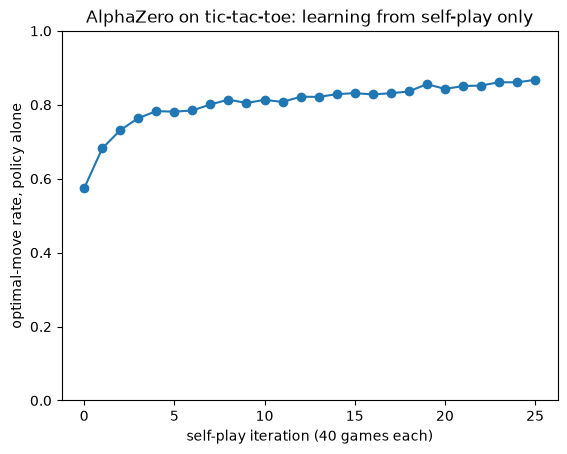

In [5]:
def self_play_game(net, sims):
    b, hist, mcts = tuple([0] * 9), [], MCTS(net, sims, noise=True)
    while terminal_value(b) is None:
        pi = mcts.run(b); hist.append((b, pi))
        a = np.random.choice(9, p=pi) if len(hist) <= 3 else int(np.argmax(pi))    # explore early in the game
        b = play(b, a)
    z = terminal_value(b)                                                    # result for the player to move at the end
    data = []
    for i, (s, pi) in enumerate(reversed(hist)): data.append((s, pi, -z if i % 2 == 0 else z))
    return data

def policy_quality(net):
    """Fraction of all reachable positions where the raw network's top move (no search) is optimal."""
    ok = sum(int(np.argmax(evaluate_net(net, b)[0])) in optimal_moves(b) for b in positions)
    return ok / len(positions)

seed_everything(0); np.random.seed(0)
net = Net(); opt = torch.optim.Adam(net.parameters(), lr=2e-3, weight_decay=1e-4)
buffer, quality = [], [policy_quality(net)]
t0 = time.time()
for it in range(25):
    for _ in range(40): buffer += self_play_game(net, sims=40)
    buffer = buffer[-6000:]
    for _ in range(150):
        batch = [buffer[i] for i in np.random.randint(0, len(buffer), 128)]
        x = torch.stack([encode(b) for b, _, _ in batch]); pi = torch.tensor(np.array([p for _, p, _ in batch]), dtype=torch.float32)
        z = torch.tensor([z for _, _, z in batch], dtype=torch.float32)
        logits, v = net(x)
        loss = F.mse_loss(v, z) - (pi * F.log_softmax(logits, -1)).sum(-1).mean()
        opt.zero_grad(); loss.backward(); opt.step()
    quality.append(policy_quality(net))
    if it % 5 == 4: print(f"iteration {it + 1:2d}: {len(buffer)} positions in buffer | raw policy plays the optimal move in {quality[-1]:.1%} of positions | {time.time() - t0:.0f}s")
plt.plot(quality, marker="o"); plt.xlabel("self-play iteration (40 games each)"); plt.ylabel("optimal-move rate, policy alone")
plt.title("AlphaZero on tic-tac-toe: learning from self-play only"); plt.ylim(0, 1); plt.show()

## Search on top of intuition, against a perfect opponent
Play 100 games against a perfect minimax player (which picks randomly among optimal moves), alternating who starts. Against perfect play, the best possible result is a draw, so we count **losses**.

In [6]:
def match(choose, games=100, seed=0):
    rng = np.random.default_rng(seed); losses = draws = 0
    for g in range(games):
        b, me = tuple([0] * 9), g % 2 == 0
        while terminal_value(b) is None:
            a = choose(b) if me else rng.choice(sorted(optimal_moves(b)))
            b = play(b, a); me = not me
        if terminal_value(b) == 0: draws += 1
        elif not me: pass
        else: losses += 1                                                    # the side to move has lost; if that's us, we lost
    return losses, draws

agents = {
    "random moves": lambda b: random.choice(legal(b)),
    "network policy alone (no search)": lambda b: int(np.argmax(evaluate_net(net, b)[0])),
    "MCTS, 40 sims, untrained network": lambda b, n0=Net(): int(np.argmax(MCTS(n0, 40).run(b))),
    "MCTS, 40 sims, trained network": lambda b: int(np.argmax(MCTS(net, 40).run(b))),
}
random.seed(0)
for name, f in agents.items():
    l, d = match(f); print(f"{name:34s} lost {l:3d} / 100 against perfect play, drew {d}")

random moves                       lost  89 / 100 against perfect play, drew 11
network policy alone (no search)   lost  10 / 100 against perfect play, drew 90


MCTS, 40 sims, untrained network   lost  59 / 100 against perfect play, drew 41


MCTS, 40 sims, trained network     lost   4 / 100 against perfect play, drew 96


## Takeaways
- **Search improves the policy, and the improved policy is the training target.** MCTS turns a network's guesses into better move distributions; the network learns to imitate them; the next search starts from better guesses. No human games and no hand-written evaluation are needed.
- **Learned evaluation replaces rollouts.** An untrained network with the same search is much weaker: the value and prior make the search efficient.
- **Scale:** AlphaZero used 5,000 TPUs for self-play and 800 simulations per move. MuZero (2019) learned the rules too, planning in a learned model. The same "generate with search or sampling, keep what verifies, train on it" loop reappears in reasoning LLMs trained with RL on verifiable rewards (notebook 69).